
N = 100000:
  Цикл с append        -> время:   7.21 мс | память:  3.82 МБ
  List comprehension   -> время:   6.16 мс | память:  3.82 МБ
  map + lambda         -> время:  10.14 мс | память:  3.82 МБ

N = 1000000:
  Цикл с append        -> время:  80.88 мс | память: 38.58 МБ
  List comprehension   -> время:  66.89 мс | память: 38.58 МБ
  map + lambda         -> время: 109.12 мс | память: 38.58 МБ


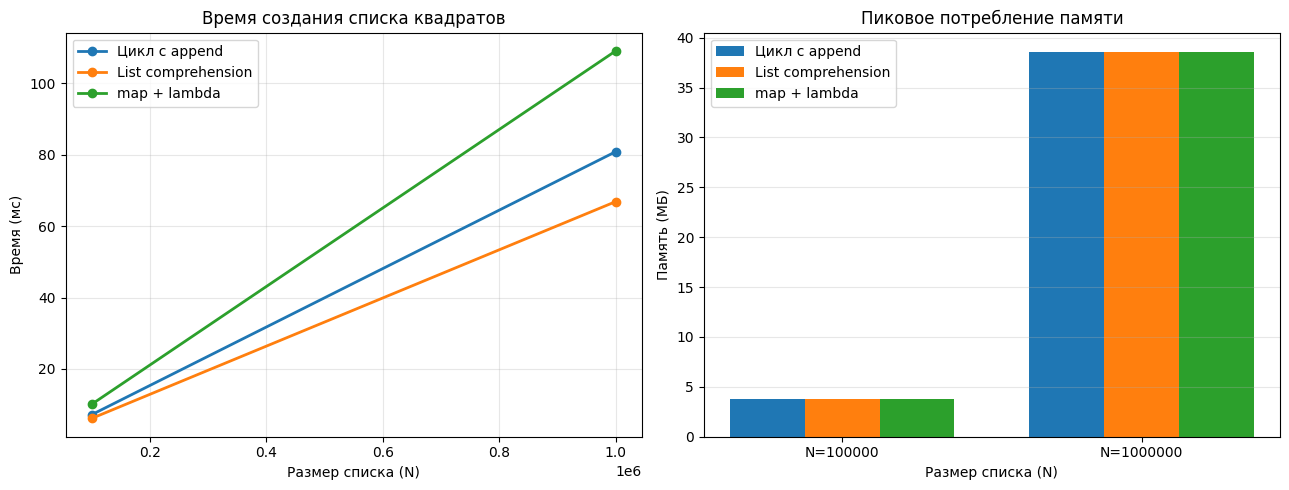


Вывод:
1. По памяти все три варианта дают одинаковый результат, так как в итоге создаётся один и тот же список чисел.
2. По времени быстрее всего работает list comprehension — он выполняется на уровне C и не тратит время на вызовы append.
3. Вариант с map и lambda самый медленный из-за постоянных вызовов lambda-функции на каждый элемент.


In [7]:
import timeit
import tracemalloc
import matplotlib.pyplot as plt

sizes = (100_000, 1_000_000)
methods = {
    "Цикл с append": "out = []\nfor i in range(N):\n    out.append(i*i)",
    "List comprehension": "out = [i*i for i in range(N)]",
    "map + lambda": "out = list(map(lambda i: i*i, range(N)))",
}

time_data = {name: [] for name in methods}
mem_data = {name: [] for name in methods}

for n in sizes:
    print(f"\nN = {n}:")
    for name, code in methods.items():
        t = min(timeit.repeat(code, globals={"N": n}, number=1, repeat=5)) * 1000
        time_data[name].append(t)

        tracemalloc.start()
        exec(code, {"N": n})
        _, peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()

        mem_mb = peak / (1024 * 1024)
        mem_data[name].append(mem_mb)

        print(f"  {name:20s} -> время: {t:6.2f} мс | память: {mem_mb:5.2f} МБ")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

for name, values in time_data.items():
    ax1.plot(sizes, values, "o-", linewidth=2, label=name)

ax1.set_title("Время создания списка квадратов")
ax1.set_xlabel("Размер списка (N)")
ax1.set_ylabel("Время (мс)")
ax1.legend()
ax1.grid(True, alpha=0.3)

x = range(len(sizes))
width = 0.25

for i, (name, values) in enumerate(mem_data.items()):
    offset = [pos + (i - 1) * width for pos in x]
    ax2.bar(offset, values, width, label=name)

ax2.set_title("Пиковое потребление памяти")
ax2.set_xlabel("Размер списка (N)")
ax2.set_ylabel("Память (МБ)")
ax2.set_xticks(list(x))
ax2.set_xticklabels([f"N={n}" for n in sizes])
ax2.legend()
ax2.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("\nВывод:")
print("1. По памяти все три варианта дают одинаковый результат, так как в итоге создаётся один и тот же список чисел.")
print("2. По времени быстрее всего работает list comprehension — он выполняется на уровне C и не тратит время на вызовы append.")
print("3. Вариант с map и lambda самый медленный из-за постоянных вызовов lambda-функции на каждый элемент.")
